<a href="https://colab.research.google.com/github/Swapnil-byte-798/Diabetes-prediction-System/blob/main/project2_capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow import keras
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.applications import ResNet50V2, VGG16, VGG19, MobileNetV2
from tensorflow.keras.applications.resnet_v2 import preprocess_input as preprocess_resnet50v2
from tensorflow.keras.applications.vgg16 import preprocess_input as preprocess_vgg16
from tensorflow.keras.applications.vgg19 import preprocess_input as preprocess_vgg19
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as preprocess_mobilenetv2
from tensorflow.keras.utils import to_categorical

In [ ]:
tf.__version__,cv2.__version__

('2.19.0', '4.12.0')

In [ ]:
!python --version

Python 3.12.12


In [ ]:
print("Available devices:")
for device in tf.config.list_physical_devices():
    print(device)

Available devices:
PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [ ]:
import os

train_folder = '/content/drive/MyDrive/Plant_Dataset/Train'
val_folder = '/content/drive/MyDrive/Plant_Dataset/Validation'

# Get class names (same in Train and Validation)
class_names = sorted(os.listdir(train_folder))
print(f"Classes: {class_names}, Total: {len(class_names)}")

# Count images in Train and Validation
total_train_images = sum(len(os.listdir(os.path.join(train_folder, cls))) for cls in class_names if os.path.isdir(os.path.join(train_folder, cls)))
total_val_images = sum(len(os.listdir(os.path.join(val_folder, cls))) for cls in class_names if os.path.isdir(os.path.join(val_folder, cls)))

print(f"Total images in Train: {total_train_images}")
print(f"Total images in Validation: {total_val_images}")
print(f"Total images in dataset: {total_train_images + total_val_images}")

Classes: ['american_bollworm_on_cotton', 'anthracnose_on_cotton', 'army_worm', 'bacterial_blight_in_cotton', 'becterial_blight_in_rice', 'bollrot_on_cotton', 'bollworm_on_cotton', 'brownspot', 'common_rust', 'cotton_aphid', 'cotton_mealy_bug', 'cotton_whitefly', 'flag_smut', 'gray_leaf_spot', 'healthy_cotton', 'healthy_maize', 'healthy_wheat', 'leaf_curl', 'leaf_smut', 'maize_ear_rot', 'maize_fall_armyworm', 'maize_stem_borer', 'mosaic_sugarcane', 'pink_bollworm_in_cotton', 'red_cotton_bug', 'redrot_sugarcane', 'redrust_sugarcane', 'rice_blast', 'sugarcane_healthy', 'thirps_on_cotton', 'tungro', 'wheat___yellow_rust', 'wheat_aphid', 'wheat_black_rust', 'wheat_brown_leaf_rust', 'wheat_leaf_blight', 'wheat_mite', 'wheat_powdery_mildew', 'wheat_scab', 'wheat_stem_fly', 'wilt', 'yellow_rust_sugarcane'], Total: 42
Total images in Train: 15349
Total images in Validation: 3174
Total images in dataset: 18523


In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

# Paths
train_folder = '/content/drive/MyDrive/Plant_Dataset/Train'
val_folder = '/content/drive/MyDrive/Plant_Dataset/Validation'
new_train_folder = '/content/drive/MyDrive/working/NewTrain'
test_folder = '/content/drive/MyDrive/working/Test'

# Create NewTrain and Test folders
os.makedirs(new_train_folder, exist_ok=True)
os.makedirs(test_folder, exist_ok=True)

# Set the test split ratio (20% for Test)
test_ratio = 0.20

# Iterate over each class in the Train folder
for class_name in os.listdir(train_folder):
    class_path = os.path.join(train_folder, class_name)

    if not os.path.isdir(class_path):
        continue

    # Get all image file names in the current class folder
    images = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

    # Split images into Train and Test
    train_imgs, test_imgs = train_test_split(images, test_size=test_ratio, random_state=42)

    # Create class folders in NewTrain and Test
    new_train_class_folder = os.path.join(new_train_folder, class_name)
    test_class_folder = os.path.join(test_folder, class_name)
    os.makedirs(new_train_class_folder, exist_ok=True)
    os.makedirs(test_class_folder, exist_ok=True)

    # Copy remaining Train images to NewTrain
    for img in train_imgs:
        src = os.path.join(class_path, img)
        dst = os.path.join(new_train_class_folder, img)
        shutil.copy2(src, dst)

    # Copy Test images to Test
    for img in test_imgs:
        src = os.path.join(class_path, img)
        dst = os.path.join(test_class_folder, img)
        shutil.copy2(src, dst)

print("NewTrain and Test folders created successfully.")

# Verify the split
total_new_train_images = sum(len(os.listdir(os.path.join(new_train_folder, cls))) for cls in os.listdir(new_train_folder) if os.path.isdir(os.path.join(new_train_folder, cls)))
total_test_images = sum(len(os.listdir(os.path.join(test_folder, cls))) for cls in os.listdir(test_folder) if os.path.isdir(os.path.join(test_folder, cls)))
print(f"Total images in NewTrain: {total_new_train_images}")
print(f"Total images in Test: {total_test_images}")
print(f"Total images in Validation: {total_val_images}")
print(f"Total images across all sets: {total_new_train_images + total_val_images + total_test_images}")

NewTrain and Test folders created successfully.
Total images in NewTrain: 12259
Total images in Test: 3083
Total images in Validation: 3174
Total images across all sets: 18516


/content/drive/MyDrive/working/NewTrain/yellow_rust_sugarcane
/content/drive/MyDrive/working/NewTrain/wilt
/content/drive/MyDrive/working/NewTrain/wheat___yellow_rust
/content/drive/MyDrive/working/NewTrain/wheat_brown_leaf_rust
/content/drive/MyDrive/working/NewTrain/wheat_stem_fly
/content/drive/MyDrive/working/NewTrain/wheat_scab
/content/drive/MyDrive/working/NewTrain/wheat_leaf_blight
/content/drive/MyDrive/working/NewTrain/wheat_mite
/content/drive/MyDrive/working/NewTrain/wheat_black_rust
/content/drive/MyDrive/working/NewTrain/wheat_powdery_mildew
/content/drive/MyDrive/working/NewTrain/wheat_aphid
/content/drive/MyDrive/working/NewTrain/tungro
/content/drive/MyDrive/working/NewTrain/thirps_on_cotton
/content/drive/MyDrive/working/NewTrain/red_cotton_bug
/content/drive/MyDrive/working/NewTrain/pink_bollworm_in_cotton
/content/drive/MyDrive/working/NewTrain/rice_blast
/content/drive/MyDrive/working/NewTrain/sugarcane_healthy
/content/drive/MyDrive/working/NewTrain/redrust_sugarc

  0%|          | 0/16 [00:00<?, ?it/s]

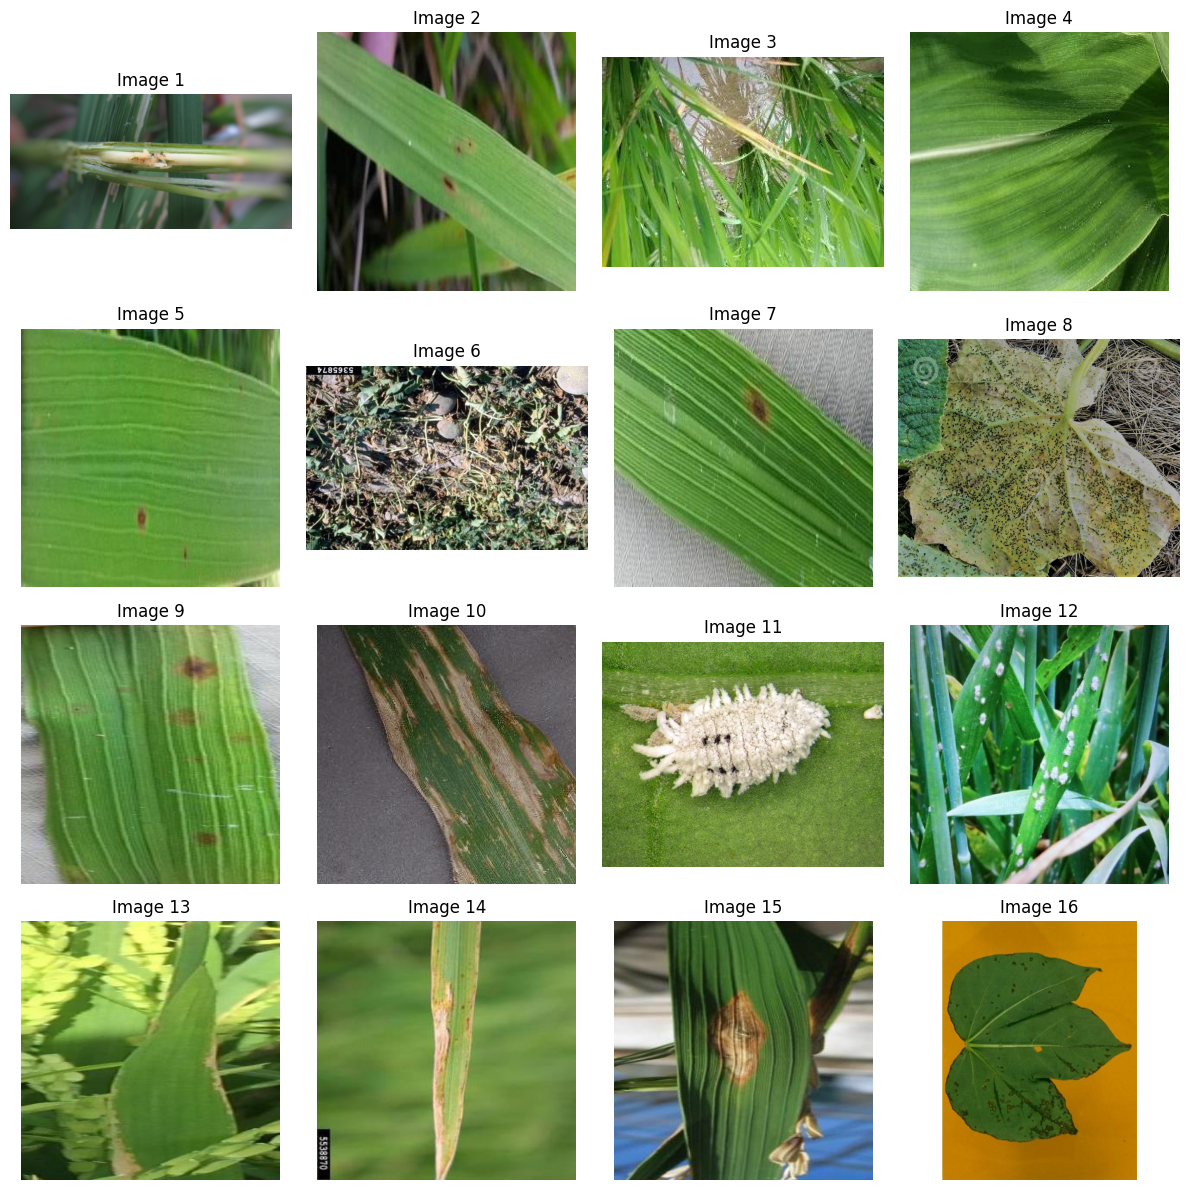

In [ ]:
# Get all image paths
images = []
for folder in os.listdir(new_train_folder):
    path = os.path.join(new_train_folder,folder)
    print(path)
    for img in os.listdir(path):
        if img.endswith(('.jpg', '.png', '.webp')):
            images.append(os.path.join(path, img))

# Pick 16 random images
random_images = random.sample(images, 16)

# Plot them
plt.figure(figsize=(12, 12))
for i, img_path in enumerate(tqdm(random_images)):
    img = cv2.imread(img_path)
    if img is None:
        continue
    img = cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
    plt.subplot(4, 4, i + 1)
    plt.imshow(img,cmap='gray')
    plt.axis('off')
    plt.title(f'Image {i+1}')

plt.tight_layout()
plt.show()

In [ ]:
val_path = '/content/drive/MyDrive/20k-multi-class-crop-disease-images/Validation'
train_path = '/content/drive/MyDrive/working/NewTrain'
test_path = '/content/drive/MyDrive/working/Test'

In [ ]:
IMG_SIZE = 224
batch_size = 32

In [ ]:
def cnn_preprocess(x):
    return x/255.0

In [ ]:
cnn_train_datagen = ImageDataGenerator(preprocessing_function=cnn_preprocess)
cnn_train_generator = cnn_train_datagen.flow_from_directory(
        train_path,
        target_size=(IMG_SIZE,IMG_SIZE),
        batch_size=batch_size,
        class_mode='categorical')

Found 12259 images belonging to 42 classes.


In [ ]:
cnn_train_generator.class_indices

{'american_bollworm_on_cotton': 0,
 'anthracnose_on_cotton': 1,
 'army_worm': 2,
 'bacterial_blight_in_cotton': 3,
 'becterial_blight_in_rice': 4,
 'bollrot_on_cotton': 5,
 'bollworm_on_cotton': 6,
 'brownspot': 7,
 'common_rust': 8,
 'cotton_aphid': 9,
 'cotton_mealy_bug': 10,
 'cotton_whitefly': 11,
 'flag_smut': 12,
 'gray_leaf_spot': 13,
 'healthy_cotton': 14,
 'healthy_maize': 15,
 'healthy_wheat': 16,
 'leaf_curl': 17,
 'leaf_smut': 18,
 'maize_ear_rot': 19,
 'maize_fall_armyworm': 20,
 'maize_stem_borer': 21,
 'mosaic_sugarcane': 22,
 'pink_bollworm_in_cotton': 23,
 'red_cotton_bug': 24,
 'redrot_sugarcane': 25,
 'redrust_sugarcane': 26,
 'rice_blast': 27,
 'sugarcane_healthy': 28,
 'thirps_on_cotton': 29,
 'tungro': 30,
 'wheat___yellow_rust': 31,
 'wheat_aphid': 32,
 'wheat_black_rust': 33,
 'wheat_brown_leaf_rust': 34,
 'wheat_leaf_blight': 35,
 'wheat_mite': 36,
 'wheat_powdery_mildew': 37,
 'wheat_scab': 38,
 'wheat_stem_fly': 39,
 'wilt': 40,
 'yellow_rust_sugarcane': 41}

In [ ]:
cnn_model = keras.Sequential([
    keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    keras.layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(filters=128, kernel_size=(3, 3), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Flatten(),
    keras.layers.Dropout(0.4),

    keras.layers.Dense(units=128, activation='relu'),
    keras.layers.Dense(units=64, activation='relu'),
    keras.layers.Dense(units=64, activation='relu'),

    keras.layers.Dense(units=len(cnn_train_generator.class_indices), activation='softmax', dtype='float32')
])

In [ ]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 42)             │         2,730 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,203,434 (42.74 MB)

 Trainable params: 11,203,434 (42.74 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        filepath='CNN_best_model.keras',
        monitor='val_loss',
        save_best_only=True,
        save_weights_only=False,
        mode='min',
        verbose=1
    )
]

In [ ]:
cnn_model.compile(optimizer=keras.optimizers.Adam(),
              loss=keras.losses.CategoricalCrossentropy(),
               metrics=['accuracy',keras.metrics.Precision(name='precision'),keras.metrics.Recall(name='recall')
])

In [ ]:
cnn_history = cnn_model.fit(
        cnn_train_generator,
        epochs = 20,
        validation_data = cnn_train_generator,
        callbacks = callbacks
        )

Epoch 1/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 0.2691 - loss: 2.7406 - precision: 0.7228 - recall: 0.1064
Epoch 1: val_loss improved from inf to 1.61780, saving model to CNN_best_model.keras
384/384 ━━━━━━━━━━━━━━━━━━━━ 234s 579ms/step - accuracy: 0.2694 - loss: 2.7394 - precision: 0.7229 - recall: 0.1067 - val_accuracy: 0.5594 - val_loss: 1.6178 - val_precision: 0.8065 - val_recall: 0.4113
Epoch 2/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.5844 - loss: 1.5244 - precision: 0.8088 - recall: 0.4392
Epoch 2: val_loss improved from 1.61780 to 1.10914, saving model to CNN_best_model.keras
384/384 ━━━━━━━━━━━━━━━━━━━━ 204s 531ms/step - accuracy: 0.5845 - loss: 1.5242 - precision: 0.8088 - recall: 0.4393 - val_accuracy: 0.6995 - val_loss: 1.1091 - val_precision: 0.8664 - val_recall: 0.5704
Epoch 3/20
384/384 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - accuracy: 0.7184 - loss: 1.0433 - precision: 0.8737 - recall: 0.6263
Epoch 3: val_loss improved from 1.10914 to 0.

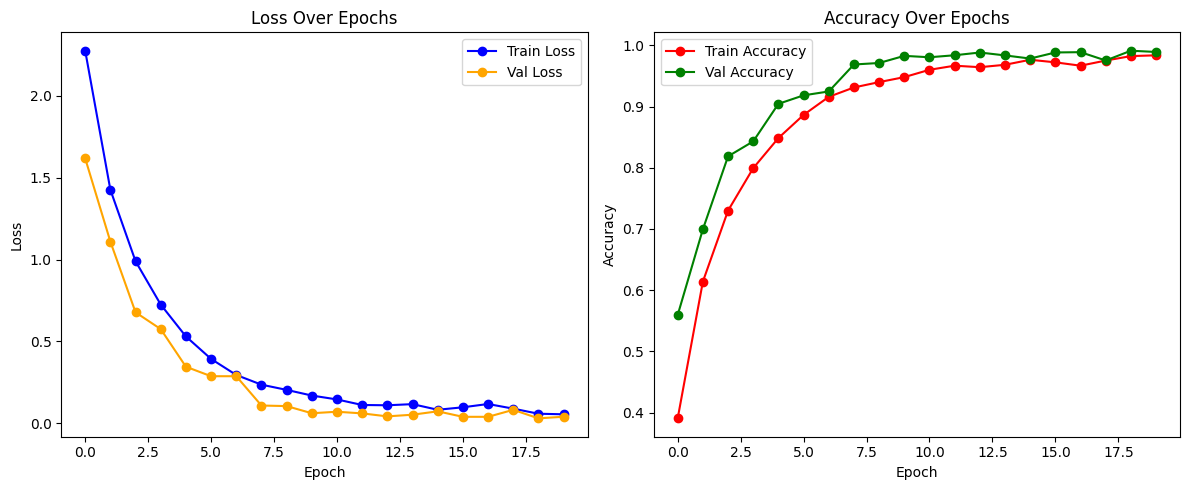

In [ ]:
# Plotting training and validation loss and accuracy
plt.figure(figsize=(12, 5))

# 📉 Loss
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history['loss'], label='Train Loss', marker='o', color='blue')
plt.plot(cnn_history.history['val_loss'], label='Val Loss', marker='o', color='orange')
plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# 📈 Accuracy
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history['accuracy'], label='Train Accuracy', marker='o', color='red')
plt.plot(cnn_history.history['val_accuracy'], label='Val Accuracy', marker='o', color='green')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
cnn_model.save('final_cnn_model.keras')
print("Model 'final_cnn_model.keras' saved successfully!")

Model 'final_cnn_model.keras' saved successfully!


You can now download the saved model using the cell below:

In [ ]:
from google.colab import files

files.download('final_cnn_model.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>